In [2]:
import os
import copy
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

import torchvision
from torchvision import datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
GPU available: True
GPU name: Tesla T4


In [3]:
# ---------------- Reproducibility & Global Config ----------------
SEED = 42

# Each group selects exactly 5 of the 10 Fashion-MNIST classes.
# Chosen here: a mix of visually SIMILAR upper-body garments (harder to
# separate) plus one clearly distinct class, to make the optimizer/
# architecture comparison meaningful. Change this list if your group
# has been assigned different classes -- nothing else needs to change.
CLASS_NAMES_FULL = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                     'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
SELECTED_CLASSES = [0, 2, 4, 6, 8]                      # T-shirt/top, Pullover, Coat, Shirt, Bag
SELECTED_NAMES   = [CLASS_NAMES_FULL[c] for c in SELECTED_CLASSES]
NUM_CLASSES = len(SELECTED_CLASSES)

# ----- Optimizer hyperparameters (fixed by the assignment spec) -----
LEARNING_RATE   = 0.001
MOMENTUM        = 0.9        # generalized delta rule & NAG
RMSPROP_ALPHA   = 0.99       # beta for RMSProp
RMSPROP_EPS     = 1e-8
ADAM_BETAS      = (0.9, 0.999)
ADAM_EPS        = 1e-8

# ----- Stopping criterion -----
CONV_THRESHOLD  = 1e-4       # |avg_loss(t) - avg_loss(t-1)| < threshold  -> converged
MAX_EPOCHS      = 40         # SAFETY CAP only (the assignment forbids epoch count as the
                              # primary criterion -- this only prevents an infinite loop if a
                              # run never satisfies the threshold; it is reported separately
                              # as `converged = False` wherever it happens).

# ----- Speed / Colab-runtime settings -----
# The assignment specifies batch_size = 1 (true, sample-by-sample SGD) for 5 of the 6
# optimizers. On ~22k training samples this means 22k+ Python-level steps PER EPOCH,
# which is impractically slow on Colab (can take hours per run x 18 runs).
# FAST_MODE turns "batch_size=1" into a small mini-batch instead, which keeps every
# optimizer's characteristic update rule intact but cuts wall-clock time drastically.
# Set FAST_MODE = False to run the assignment EXACTLY as specified (batch_size=1)
# if you have GPU time to spare -- it will be much slower.
FAST_MODE = True
SGD_FAMILY_BATCH_SIZE = 64 if FAST_MODE else 1   # used for SGD, Momentum, NAG, RMSProp, Adam
EVAL_BATCH_SIZE = 256                             # only affects evaluation speed, not results

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Selected classes:", SELECTED_NAMES)
print("Using device:", DEVICE)
print(f"FAST_MODE={FAST_MODE}  ->  batch size for SGD-family optimizers = {SGD_FAMILY_BATCH_SIZE}")


Selected classes: ['T-shirt/top', 'Pullover', 'Coat', 'Shirt', 'Bag']
Using device: cuda
FAST_MODE=True  ->  batch size for SGD-family optimizers = 64


In [4]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)


In [5]:
DATA_ROOT = './data'

try:
    train_raw = datasets.FashionMNIST(root=DATA_ROOT, train=True,  download=True)
    test_raw  = datasets.FashionMNIST(root=DATA_ROOT, train=False, download=True)
    images = torch.cat([train_raw.data, test_raw.data], dim=0).numpy()          # (70000, 28, 28) uint8
    labels = torch.cat([train_raw.targets, test_raw.targets], dim=0).numpy()    # (70000,)
    print("Loaded Fashion-MNIST via torchvision.")
except Exception as e1:
    print("torchvision download failed:", e1)
    print("Falling back to tensorflow.keras's bundled copy of the same dataset...")
    try:
        from tensorflow.keras.datasets import fashion_mnist
        (X_tr, y_tr), (X_te, y_te) = fashion_mnist.load_data()
        images = np.concatenate([X_tr, X_te], axis=0)
        labels = np.concatenate([y_tr, y_te], axis=0)
        print("Loaded Fashion-MNIST via tensorflow.keras.")
    except Exception as e2:
        raise RuntimeError(
            "Both torchvision and tensorflow.keras downloads failed "
            f"({e1!r}, {e2!r}). Please use the optional Kaggle download cell below instead."
        )

print("Pooled dataset:", images.shape, labels.shape)


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.74MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.9MB/s]

Loaded Fashion-MNIST via torchvision.
Pooled dataset: (70000, 28, 28) (70000,)


In [6]:
mask = np.isin(labels, SELECTED_CLASSES)
X_selected = images[mask]
y_selected_orig = labels[mask]

label_map = {orig: new for new, orig in enumerate(SELECTED_CLASSES)}   # e.g. {0:0, 2:1, 4:2, 6:3, 8:4}
y_selected = np.array([label_map[int(l)] for l in y_selected_orig], dtype=np.int64)

print("After discarding the other 5 classes:", X_selected.shape, y_selected.shape)
print("Remapped label  <-  original class:")
for orig, new in label_map.items():
    print(f"  {new}  <-  {orig} ({CLASS_NAMES_FULL[orig]})")


After discarding the other 5 classes: (35000, 28, 28) (35000,)
Remapped label  <-  original class:
  0  <-  0 (T-shirt/top)
  1  <-  2 (Pullover)
  2  <-  4 (Coat)
  3  <-  6 (Shirt)
  4  <-  8 (Bag)


In [7]:
X_norm = X_selected.astype(np.float32) / 255.0        # scale to [0, 1]
X_flat = X_norm.reshape(X_norm.shape[0], -1)           # flatten 28x28 -> 784

print("Flattened, normalized feature matrix:", X_flat.shape, "dtype:", X_flat.dtype)
print("Pixel value range:", X_flat.min(), "to", X_flat.max())


Flattened, normalized feature matrix: (35000, 784) dtype: float32
Pixel value range: 0.0 to 1.0


In [8]:
X_trainfull, X_test, y_trainfull, y_test = train_test_split(
    X_flat, y_selected, test_size=0.20, stratify=y_selected, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainfull, y_trainfull, test_size=0.20, stratify=y_trainfull, random_state=SEED
)

total = len(y_selected)
print(f"Train: {len(y_train):6d}  ({len(y_train)/total*100:5.1f}%)")
print(f"Val:   {len(y_val):6d}  ({len(y_val)/total*100:5.1f}%)")
print(f"Test:  {len(y_test):6d}  ({len(y_test)/total*100:5.1f}%)")

split_check = pd.DataFrame({
    'train': pd.Series(y_train).value_counts().sort_index(),
    'val':   pd.Series(y_val).value_counts().sort_index(),
    'test':  pd.Series(y_test).value_counts().sort_index(),
})
split_check.index = [SELECTED_NAMES[i] for i in split_check.index]
split_check


Train:  22400  ( 64.0%)
Val:     5600  ( 16.0%)
Test:    7000  ( 20.0%)


,train,val,test
T-shirt/top,4480,1120,1400
Pullover,4480,1120,1400
Coat,4480,1120,1400
Shirt,4480,1120,1400
Bag,4480,1120,1400


In [9]:
def to_tensor_dataset(X, y):
    return TensorDataset(torch.from_numpy(X).float(), torch.from_numpy(y).long())

train_ds = to_tensor_dataset(X_train, y_train)
val_ds   = to_tensor_dataset(X_val,   y_val)
test_ds  = to_tensor_dataset(X_test,  y_test)

def make_loader(dataset, batch_size, shuffle):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0)

val_loader  = make_loader(val_ds,  EVAL_BATCH_SIZE, shuffle=False)
test_loader = make_loader(test_ds, EVAL_BATCH_SIZE, shuffle=False)

print("Train dataset:", len(train_ds), " Val dataset:", len(val_ds), " Test dataset:", len(test_ds))


Train dataset: 22400  Val dataset: 5600  Test dataset: 7000


In [10]:
class FCNN(nn.Module):
    # Fully connected network with a configurable number of hidden layers (3-5).
    def __init__(self, input_dim, hidden_sizes, output_dim):
        super().__init__()
        assert 3 <= len(hidden_sizes) <= 5, "Assignment requires 3 to 5 hidden layers."
        layers = []
        prev_dim = input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(nn.ReLU())
            prev_dim = h
        layers.append(nn.Linear(prev_dim, output_dim))   # raw logits
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


In [11]:
ARCHITECTURES = {
    'Arch_3HL': [256, 128, 64],           # 3 hidden layers
    'Arch_4HL': [256, 128, 64, 32],       # 4 hidden layers
    'Arch_5HL': [512, 256, 128, 64, 32],  # 5 hidden layers
}
for name, sizes in ARCHITECTURES.items():
    print(f"{name}: input(784) -> " + " -> ".join(str(s) for s in sizes) + f" -> output({NUM_CLASSES})")


Arch_3HL: input(784) -> 256 -> 128 -> 64 -> output(5)
Arch_4HL: input(784) -> 256 -> 128 -> 64 -> 32 -> output(5)
Arch_5HL: input(784) -> 512 -> 256 -> 128 -> 64 -> 32 -> output(5)


In [12]:
@torch.no_grad()
def evaluate_accuracy(model, loader, device):
    model.eval()
    correct, total = 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        preds = model(xb).argmax(dim=1)
        correct += (preds == yb).sum().item()
        total += yb.size(0)
    return correct / total

@torch.no_grad()
def get_all_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        preds = model(xb).argmax(dim=1).cpu().numpy()
        all_preds.append(preds)
        all_labels.append(yb.numpy())
    return np.concatenate(all_preds), np.concatenate(all_labels)


In [13]:
def train_model(model, optimizer, train_loader, val_loader, device,
                 threshold=CONV_THRESHOLD, max_epochs=MAX_EPOCHS, verbose=False):
    # Trains `model` until the absolute difference between successive epochs'
    # average training loss falls below `threshold` (the assignment's stopping
    # criterion). `max_epochs` is only a safety cap in case that never happens.
    model.to(device)
    criterion = nn.CrossEntropyLoss()

    history = {'train_loss': [], 'train_acc': [], 'val_acc': []}
    prev_avg_loss = None
    converged_epoch = max_epochs
    converged = False

    for epoch in range(1, max_epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            outputs = model(xb)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            correct += (outputs.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)

        avg_loss = running_loss / total
        train_acc = correct / total
        val_acc = evaluate_accuracy(model, val_loader, device)

        history['train_loss'].append(avg_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if verbose:
            print(f"  epoch {epoch:3d}  train_loss={avg_loss:.5f}  train_acc={train_acc:.4f}  val_acc={val_acc:.4f}")

        if prev_avg_loss is not None and abs(prev_avg_loss - avg_loss) < threshold:
            converged_epoch = epoch
            converged = True
            break
        prev_avg_loss = avg_loss

    return history, converged_epoch, converged


In [14]:
OPTIMIZER_NAMES = ['SGD', 'BGD', 'Momentum', 'NAG', 'RMSProp', 'Adam']

def get_optimizer(name, params):
    if name == 'SGD':
        return optim.SGD(params, lr=LEARNING_RATE)
    elif name == 'BGD':
        return optim.SGD(params, lr=LEARNING_RATE)                     # same update rule, just full-batch data
    elif name == 'Momentum':
        return optim.SGD(params, lr=LEARNING_RATE, momentum=MOMENTUM)
    elif name == 'NAG':
        return optim.SGD(params, lr=LEARNING_RATE, momentum=MOMENTUM, nesterov=True)
    elif name == 'RMSProp':
        return optim.RMSprop(params, lr=LEARNING_RATE, alpha=RMSPROP_ALPHA, eps=RMSPROP_EPS)
    elif name == 'Adam':
        return optim.Adam(params, lr=LEARNING_RATE, betas=ADAM_BETAS, eps=ADAM_EPS)
    else:
        raise ValueError(f"Unknown optimizer: {name}")

def get_batch_size(name, n_train):
    return n_train if name == 'BGD' else SGD_FAMILY_BATCH_SIZE


In [15]:
results = {}   # results[arch_name][opt_name] = {history, converged_epoch, converged, model, time_sec, ...}

for arch_name, hidden_sizes in ARCHITECTURES.items():
    print(f"\n{'='*70}\nArchitecture: {arch_name}  {hidden_sizes}\n{'='*70}")

    # Build once per architecture and freeze the initial weights so every
    # optimizer for this architecture starts from an IDENTICAL initialization.
    set_seed(SEED)
    init_model = FCNN(784, hidden_sizes, NUM_CLASSES)
    initial_state = copy.deepcopy(init_model.state_dict())

    results[arch_name] = {}
    for opt_name in OPTIMIZER_NAMES:
        model = FCNN(784, hidden_sizes, NUM_CLASSES)
        model.load_state_dict(initial_state)     # identical starting weights every time

        batch_size = get_batch_size(opt_name, len(train_ds))
        train_loader = make_loader(train_ds, batch_size, shuffle=True)
        optimizer = get_optimizer(opt_name, model.parameters())

        t0 = time.time()
        history, converged_epoch, converged = train_model(model, optimizer, train_loader, val_loader, DEVICE)
        elapsed = time.time() - t0

        results[arch_name][opt_name] = {
            'history': history,
            'converged_epoch': converged_epoch,
            'converged': converged,
            'model': model,
            'time_sec': elapsed,
            'final_train_acc': history['train_acc'][-1],
            'final_val_acc': history['val_acc'][-1],
            'best_val_acc': max(history['val_acc']),
        }
        tag = "converged" if converged else "hit MAX_EPOCHS cap"
        print(f"  {opt_name:9s}: {converged_epoch:3d} epochs ({tag}) | "
              f"train_acc={history['train_acc'][-1]:.4f}  val_acc={history['val_acc'][-1]:.4f}  "
              f"[{elapsed:.1f}s]")

total_time = sum(results[a][o]['time_sec'] for a in ARCHITECTURES for o in OPTIMIZER_NAMES)
print(f"\nAll experiments complete. Total wall-clock time: {total_time/60:.1f} minutes")



Architecture: Arch_3HL  [256, 128, 64]
  SGD      :  40 epochs (hit MAX_EPOCHS cap) | train_acc=0.6938  val_acc=0.6937  [32.8s]
  BGD      :   2 epochs (converged) | train_acc=0.0772  val_acc=0.0796  [0.7s]
  Momentum :  40 epochs (hit MAX_EPOCHS cap) | train_acc=0.8513  val_acc=0.8227  [32.4s]
  NAG      :  40 epochs (hit MAX_EPOCHS cap) | train_acc=0.8548  val_acc=0.8266  [38.9s]
  RMSProp  :  40 epochs (hit MAX_EPOCHS cap) | train_acc=0.9351  val_acc=0.8363  [35.1s]
  Adam     :  40 epochs (hit MAX_EPOCHS cap) | train_acc=0.9386  val_acc=0.8482  [37.8s]

Architecture: Arch_4HL  [256, 128, 64, 32]
  SGD      :  40 epochs (hit MAX_EPOCHS cap) | train_acc=0.6268  val_acc=0.6080  [34.2s]
  BGD      :   2 epochs (converged) | train_acc=0.2000  val_acc=0.1998  [0.5s]
  Momentum :  40 epochs (hit MAX_EPOCHS cap) | train_acc=0.8482  val_acc=0.8137  [35.2s]
  NAG      :  40 epochs (hit MAX_EPOCHS cap) | train_acc=0.8521  val_acc=0.8239  [38.7s]
  RMSProp  :  40 epochs (hit MAX_EPOCHS cap) |

In [17]:
epochs_table = pd.DataFrame({
    opt: [results[arch][opt]['converged_epoch'] for arch in ARCHITECTURES]
    for opt in OPTIMIZER_NAMES
}, index=list(ARCHITECTURES.keys()))
print("Epochs to convergence (or MAX_EPOCHS cap) per architecture x optimizer:")
epochs_table


Epochs to convergence (or MAX_EPOCHS cap) per architecture x optimizer:


,SGD,BGD,Momentum,NAG,RMSProp,Adam
Arch_3HL,40,2,40,40,40,40
Arch_4HL,40,2,40,40,40,40
Arch_5HL,40,2,40,40,40,40


In [18]:
rows = []
for arch in ARCHITECTURES:
    for opt in OPTIMIZER_NAMES:
        r = results[arch][opt]
        rows.append({
            'Architecture': arch,
            'Optimizer': opt,
            'Epochs': r['converged_epoch'],
            'Converged': r['converged'],
            'Train Acc': round(r['final_train_acc'], 4),
            'Val Acc': round(r['final_val_acc'], 4),
            'Best Val Acc': round(r['best_val_acc'], 4),
        })
accuracy_table = pd.DataFrame(rows)
accuracy_table


,Architecture,Optimizer,Epochs,Converged,Train Acc,Val Acc,Best Val Acc
0,Arch_3HL,SGD,40,False,0.6938,0.6937,0.6937
1,Arch_3HL,BGD,2,True,0.0772,0.0796,0.0796
2,Arch_3HL,Momentum,40,False,0.8513,0.8227,0.8268
3,Arch_3HL,NAG,40,False,0.8548,0.8266,0.8271
4,Arch_3HL,RMSProp,40,False,0.9351,0.8363,0.8541
5,Arch_3HL,Adam,40,False,0.9386,0.8482,0.8538
6,Arch_4HL,SGD,40,False,0.6268,0.6080,0.6177
7,Arch_4HL,BGD,2,True,0.2000,0.1998,0.1998
8,Arch_4HL,Momentum,40,False,0.8482,0.8137,0.8263
9,Arch_4HL,NAG,40,False,0.8521,0.8239,0.8268


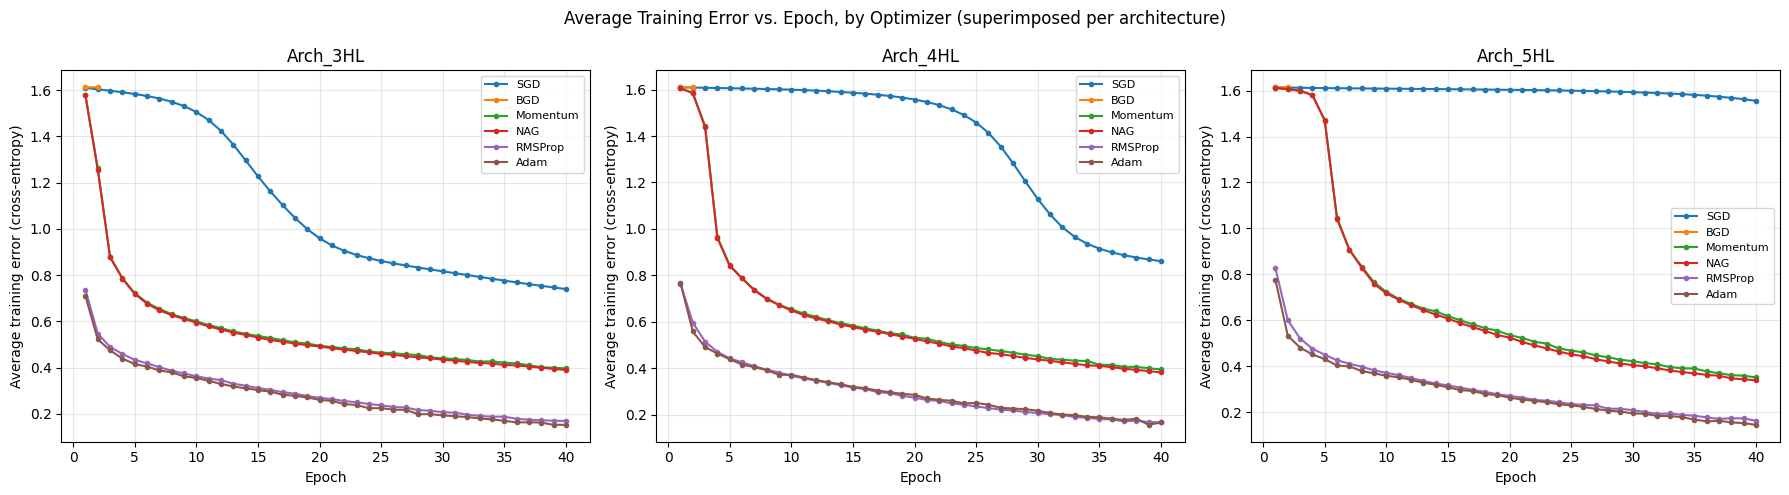

In [19]:
fig, axes = plt.subplots(1, len(ARCHITECTURES), figsize=(6*len(ARCHITECTURES), 5), sharey=False)
if len(ARCHITECTURES) == 1:
    axes = [axes]

for ax, arch_name in zip(axes, ARCHITECTURES.keys()):
    for opt_name in OPTIMIZER_NAMES:
        loss_curve = results[arch_name][opt_name]['history']['train_loss']
        ax.plot(range(1, len(loss_curve)+1), loss_curve, label=opt_name, marker='o', markersize=3)
    ax.set_title(arch_name)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Average training error (cross-entropy)')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('Average Training Error vs. Epoch, by Optimizer (superimposed per architecture)')
plt.tight_layout()
plt.savefig('loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()


In [20]:
best_arch, best_opt, best_val = None, None, -1
for arch in ARCHITECTURES:
    for opt in OPTIMIZER_NAMES:
        v = results[arch][opt]['best_val_acc']
        if v > best_val:
            best_val, best_arch, best_opt = v, arch, opt

print(f"Best architecture (by validation accuracy): {best_arch}  {ARCHITECTURES[best_arch]}")
print(f"Best optimizer for that architecture:        {best_opt}")
print(f"Best validation accuracy achieved:            {best_val:.4f}")

best_model = results[best_arch][best_opt]['model']


Best architecture (by validation accuracy): Arch_4HL  [256, 128, 64, 32]
Best optimizer for that architecture:        RMSProp
Best validation accuracy achieved:            0.8593


[Arch_4HL / RMSProp]  Final Training Accuracy: 0.9396
[Arch_4HL / RMSProp]  Final Test Accuracy:     0.8499

Test classification report:
              precision    recall  f1-score   support

 T-shirt/top       0.83      0.91      0.87      1400
    Pullover       0.76      0.89      0.82      1400
        Coat       0.87      0.81      0.84      1400
       Shirt       0.82      0.66      0.73      1400
         Bag       0.99      0.97      0.98      1400

    accuracy                           0.85      7000
   macro avg       0.85      0.85      0.85      7000
weighted avg       0.85      0.85      0.85      7000



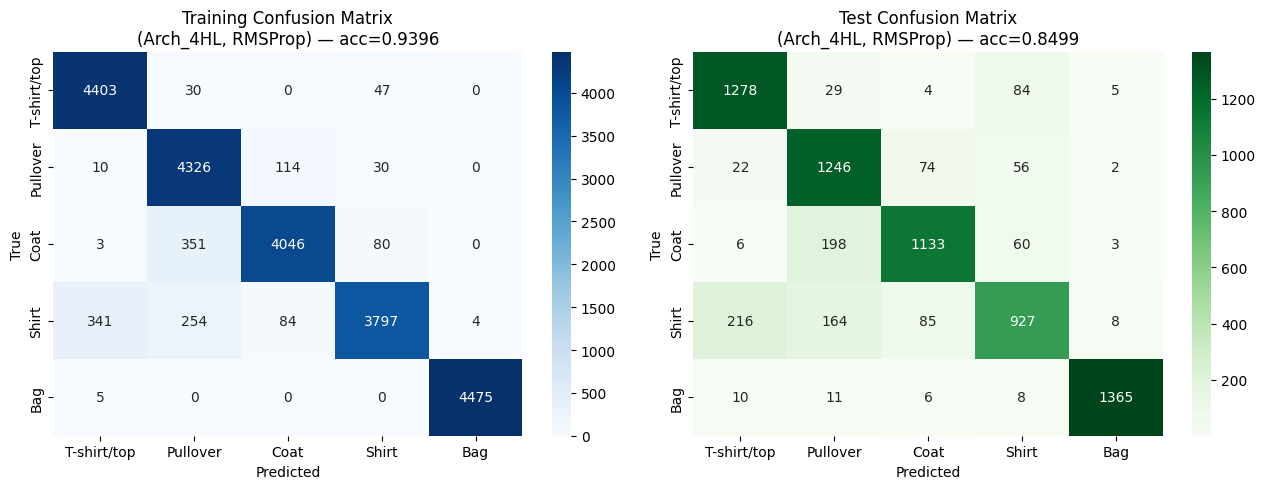

In [21]:
train_loader_eval = make_loader(train_ds, EVAL_BATCH_SIZE, shuffle=False)
train_preds, train_labels = get_all_predictions(best_model, train_loader_eval, DEVICE)
test_preds,  test_labels  = get_all_predictions(best_model, test_loader,  DEVICE)

train_acc_final = accuracy_score(train_labels, train_preds)
test_acc_final  = accuracy_score(test_labels,  test_preds)

print(f"[{best_arch} / {best_opt}]  Final Training Accuracy: {train_acc_final:.4f}")
print(f"[{best_arch} / {best_opt}]  Final Test Accuracy:     {test_acc_final:.4f}\n")
print("Test classification report:")
print(classification_report(test_labels, test_preds, target_names=SELECTED_NAMES))

cm_train = confusion_matrix(train_labels, train_preds, labels=list(range(NUM_CLASSES)))
cm_test  = confusion_matrix(test_labels,  test_preds,  labels=list(range(NUM_CLASSES)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues',
            xticklabels=SELECTED_NAMES, yticklabels=SELECTED_NAMES, ax=axes[0])
axes[0].set_title(f'Training Confusion Matrix\n({best_arch}, {best_opt}) — acc={train_acc_final:.4f}')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens',
            xticklabels=SELECTED_NAMES, yticklabels=SELECTED_NAMES, ax=axes[1])
axes[1].set_title(f'Test Confusion Matrix\n({best_arch}, {best_opt}) — acc={test_acc_final:.4f}')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()


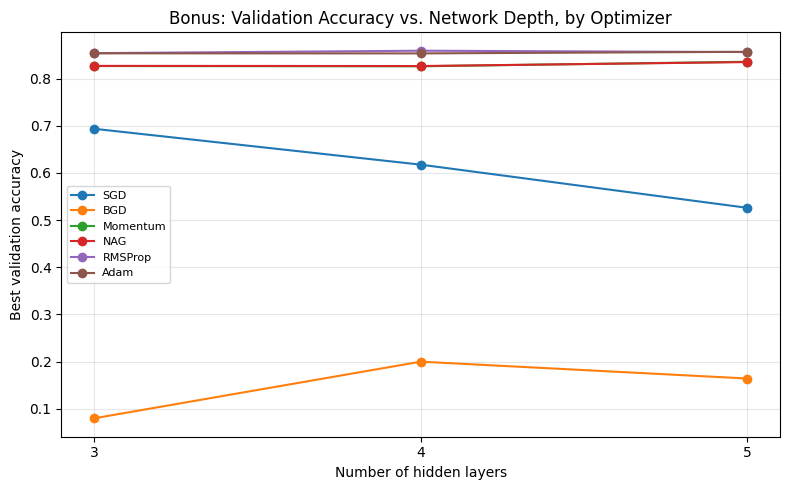

In [22]:
plt.figure(figsize=(8, 5))
depths = [len(ARCHITECTURES[a]) for a in ARCHITECTURES]
for opt in OPTIMIZER_NAMES:
    vals = [results[arch][opt]['best_val_acc'] for arch in ARCHITECTURES]
    plt.plot(depths, vals, marker='o', label=opt)
plt.xticks(depths)
plt.xlabel('Number of hidden layers')
plt.ylabel('Best validation accuracy')
plt.title('Bonus: Validation Accuracy vs. Network Depth, by Optimizer')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('bonus_depth_vs_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()


In [23]:
print("Quick auto-generated insights (use these as a starting point for your written observations):\n")

epochs_float = epochs_table.loc[:, OPTIMIZER_NAMES].astype(float)
for arch in ARCHITECTURES:
    row = epochs_float.loc[arch]
    print(f"- {arch}: fastest-converging optimizer = {row.idxmin()} ({int(row.min())} epochs), "
          f"slowest = {row.idxmax()} ({int(row.max())} epochs)")

print()
mean_epochs_by_opt = epochs_float.mean(axis=0).sort_values()
print("Average epochs-to-convergence across all 3 architectures, per optimizer:")
print(mean_epochs_by_opt.round(1).to_string())

print(f"\nOverall best (architecture, optimizer) by validation accuracy: ({best_arch}, {best_opt}) -> {best_val:.4f}")


Quick auto-generated insights (use these as a starting point for your written observations):

- Arch_3HL: fastest-converging optimizer = BGD (2 epochs), slowest = SGD (40 epochs)
- Arch_4HL: fastest-converging optimizer = BGD (2 epochs), slowest = SGD (40 epochs)
- Arch_5HL: fastest-converging optimizer = BGD (2 epochs), slowest = SGD (40 epochs)

Average epochs-to-convergence across all 3 architectures, per optimizer:
BGD          2.0
SGD         40.0
Momentum    40.0
NAG         40.0
RMSProp     40.0
Adam        40.0

Overall best (architecture, optimizer) by validation accuracy: (Arch_4HL, RMSProp) -> 0.8593
